# **Computer Vision Track - Assignment 1**
## **Artificial Neural Network for Image Classification**

In this assignment, we explore the fundamentals of building a neural network for image classification. Image classification is a core task in computer vision, where the goal is to correctly identify and categorize objects in images. We will design and implement a neural network using popular machine learning libraries, applying key concepts such as activation functions and backpropagation. By training the model on a labeled dataset, we aim to evaluate its performance and understand how different network architectures influence classification accuracy. This assignment serves as a practical introduction to deep learning in computer vision.

> **MISSION LOG - Day 1**
>
> To bring back Mary's image recognition software which will help you in navigation, you have to build it up from the basics
>
> **Your first repair job:** Make a simplified version of Mary which can read and understand handwritten numbers from 0-9 using the popular MNIST dataset (Which you conveniently thought to pack on your trip)

====================================================================================================

### **Before you start**

1) **Save your own copy:** *File → Save a copy in Drive*, and work in that copy.
2) **Fill in every `None`.** Each one has a `TODO` comment (and often a hint) telling you what belongs there.
3) **Run the cells in order, from top to bottom.** If you skip one, later cells will fail.
4) **A GPU is optional.** This assignment is small enough to run on a CPU. If you want a GPU: *Runtime → Change runtime type → choose a GPU (e.g. T4) → Save*. You will see which one you are using in Step 2.
5) **If a cell shows an error**, read the *last line* of the error message first. It usually tells you what went wrong.
6) At the end there are **a few short written questions**. Answer them in your own words.

### **The big picture (read this once before coding)**

To a computer, an image is just a grid of numbers. A handwritten digit in MNIST is a 28 x 28 grid, which is 784 numbers (0 = black, 255 = white). Our job is to build a function that turns those 784 numbers into the right answer, 0 to 9.

That function is a **neural network**: layers of simple units whose connections have adjustable numbers called **weights**. At the start the weights are random, so the network's guesses are rubbish. Then we repeat this cycle many times:

1) **Guess:** show the network a batch of images and let it predict.
2) **Measure the mistake:** the **loss** is one number saying how wrong the guesses were.
3) **Work out the fix:** **backpropagation** calculates, for every weight, which direction would reduce the loss.
4) **Nudge the weights:** the **optimizer** moves each weight a tiny step in that direction.

One full pass through all the training images is called an **epoch**. Training is just many epochs of this cycle. The steps below fill in each part.

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 1**

The code below imports essential libraries for building and training an artificial neural network (ANN) using PyTorch.
1) <blue>**torch**</blue> and <blue>**torch.nn**</blue> provide core functionality for tensors and neural networks.
2) <blue>**optim**</blue> offers optimization algorithms (like <green>**Adam**</green>).
3) <blue>**torchvision**</blue> helps with image-related tasks, and transforms aids in image preprocessing.
4) <blue>**DataLoader**</blue> is used to load datasets in batches.
5) Libraries like <blue>**matplotlib**</blue>, <blue>**seaborn**</blue>, and <blue>**sklearn.metrics**</blue> help visualize results and evaluate the model using metrics such as <green>**accuracy**</green>, <green>**precision**</green>, <green>**recall**</green> etc.
6) The <blue>**random seed**</blue> makes the random starting weights the same each time, so your results are repeatable.

In [3]:
# Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import numpy as np

# Fix the random seed so results are repeatable
torch.manual_seed(42)
np.random.seed(42)

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 2**
1) The <blue>**device**</blue> variable ensures the model runs on a <green>**GPU**</green> if available; otherwise, it falls back to a <green>**CPU**</green>.
2) The <blue>**transform**</blue> object defines the <green>**preprocessing**</green> steps for images
3) <blue>**ToTensor()**</blue> converts images to tensors.
4) <blue>**Normalize((0.5,), (0.5,))**</blue> normalizes the images to a range between -1 and 1, helping with better convergence during training.

In [4]:
# Set device (GPU if available, else CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Running on:", device)

# Define the transformations (Normalization)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # Normalize the dataset to range [-1, 1]
])

Running on: cpu


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 3**
1) This code outlines loading the <blue>**MNIST**</blue> dataset for <green>**handwritten digit recognition**</green>.
2) MNIST comes in two parts: <blue>**60,000 training images**</blue> that the network learns from, and <blue>**10,000 test images**</blue> that it never sees while learning. Think of the test set as a <green>**hidden exam paper**</green>: it is the only fair way to find out whether the network learned the digits or just memorised the practice questions.
3) The <blue>**train_loader**</blue> and <blue>**test_loader**</blue> are used to load the datasets in batches of 64, with shuffling applied only to the training set.

Note: The placeholders **"None"** need to be replaced with the correct dataset-loading code. Use `torchvision.datasets.MNIST(...)` with `train=True` for the training set and `train=False` for the test set. Don't forget `download=True` and the `transform` from Step 2.

In [5]:
# Load the MNIST Dataset
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [00:02<00:00, 4610633.66it/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 117087.62it/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 503: Service Unavailable



100%|██████████| 1648877/1648877 [00:01<00:00, 1102495.14it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 503: Service Unavailable



100%|██████████| 4542/4542 [00:00<00:00, 3309106.96it/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



Let's look at the data. The next cell prints the shape of one batch and shows 16 of its images with their labels. Nothing to fill in here. Run it and check that the pictures match their labels.

Batch of images: torch.Size([64, 1, 28, 28])
Batch of labels: torch.Size([64])


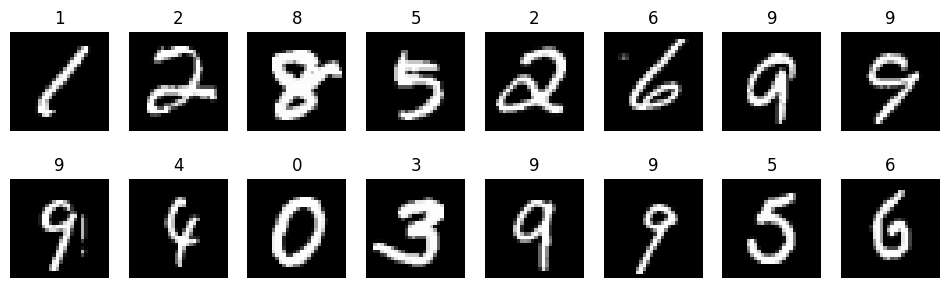

In [6]:
# Look at one batch: 64 images of 28x28 pixels, with their labels
dataiter = iter(train_loader)
images, labels = next(dataiter)
print("Batch of images:", images.shape)   # (batch size, channels, height, width)
print("Batch of labels:", labels.shape)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(int(lab))
    ax.axis('off')
plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 4**
1) This code defines a simple <green>**feedforward artificial neural network (ANN)**</green> for classifying MNIST digits.
2) The model has three fully connected layers <blue>**(fc1, fc2, fc3)**</blue>, and the final layer outputs predictions for <green>**10 classes (digits 0-9)**</green>.
3) The <green>**forward pass**</green> describes how the input data flows through the network
4) The input image is first <green>**flattened**</green> from a 28 x 28 grid into one list of 784 numbers.
5) It passes through fully connected layers with <blue>**ReLU activation function**</blue>. ReLU simply turns negative numbers into 0 and keeps positive numbers as they are. Without an activation function between layers, the whole network could only learn straight-line relationships.
6) The last layer has <green>**no activation**</green> here, because the loss function in Step 5 handles that part for us.

Note: Replace the placeholders **"None"** with the appropriate numbers of units and activation functions in each layer. The number of units in the hidden layers is your choice (try a set of numbers bridging the difference between the number of input and output neurons), but the **output size of one layer must equal the input size of the next**.

In [7]:
# Define the neural network model
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()
        # TODO: Define the layers (Fully Connected layers)
        #self.fc1 = nn.Linear(28*28, None)  # Replace None with the number of units
        self.fc1 = nn.Linear(28*28, 256)  # Input: 784, Output: 256
        #self.fc2 = # Replace None with the number of units
        self.fc2 = nn.Linear(256, 128) # Input: 256, Output: 128
        #self.fc3 = # Output layer for 10 classes
        self.fc3 = nn.Linear(128, 10) # Input: 128, Output: 10

    def forward(self, x):
        # TODO: Implement the forward pass
        # Flatten the image from 28x28 to 784 features
        x = x.view(-1, 28*28)  # Flatten the image
        #x = None  # First fully connected layer + ReLU activation
        x = torch.relu(self.fc1(x))
        #x = None  # Second fully connected layer + ReLU activation
        x = torch.relu(self.fc2(x))
        #x = None  # Output layer (no activation)
        x = self.fc3(x)
        return x

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 5**
1) The <blue>**ANN model**</blue> is instantiated and moved to the <green>**selected device (CPU or GPU)**</green>.
2) The loss function is set to <blue>**CrossEntropyLoss**</blue>, which is suitable for <green>**multi-class classification**</green> problems like MNIST. It gives a large loss when the network is confidently wrong.
3) The optimizer is <blue>**Adam**</blue>, with a <blue>**learning rate**</blue> of <green>**0.001**</green>, used to adjust the model parameters during training based on gradients computed from the loss. The learning rate is the size of each nudge: too big and training becomes unstable, too small and it crawls.

In [8]:
# Initialize the model, loss function, and optimizer
model = ANN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 6**
This code trains the neural network over a specified number of epochs (num_epochs).
For each batch of images and labels, the following steps are performed:
1) <blue>**Data Movement**</blue>: Images and labels are moved to the <green>**device (CPU or GPU)**</green>.
2) <blue>**Forward Pass**</blue>: Images pass through the network to compute the <green>**output predictions**</green>.
3) <blue>**Loss Calculation**</blue>: The loss between the predictions and true labels is computed and added to <blue>**ls_losses**</blue> for tracking.
4) <blue>**Backpropagation and Optimization**</blue>: three lines that form the heart of all deep learning:
   - `optimizer.zero_grad()` clears the gradients left over from the previous batch,
   - `loss.backward()` works out how each weight should change to reduce the loss,
   - `optimizer.step()` actually changes the weights.

Every 100 batches, the loss is printed to monitor training progress.

Note: Choose a small number of epochs. The model and the data both have to be on the **same device**, so move the images and labels to `device`.

In [9]:
# Training the network
model.train()  # Put the model in training mode
#num_epochs = None  # Choose the number of epochs (15 or lower)
num_epochs = 10
ls_losses = []
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        # TODO: Move images and labels to the device
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        #outputs = None  # Forward pass through the model
        outputs = model(images)
        #loss = None     # Compute the loss between the outputs and the labels
        loss = criterion(outputs, labels)
        ls_losses.append(loss.item())  # Store the loss (as a plain number) for plotting later

        # Backward and optimize
        optimizer.zero_grad()  # Clear old gradients
        #None  # Backward pass
        loss.backward()
        #None  # Optimize the weights
        optimizer.step() 

        if (i+1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}')

Epoch [1/10], Step [100/938], Loss: 0.3550
Epoch [1/10], Step [200/938], Loss: 0.3800
Epoch [1/10], Step [300/938], Loss: 0.3166
Epoch [1/10], Step [400/938], Loss: 0.2891
Epoch [1/10], Step [500/938], Loss: 0.2305
Epoch [1/10], Step [600/938], Loss: 0.4003
Epoch [1/10], Step [700/938], Loss: 0.3421
Epoch [1/10], Step [800/938], Loss: 0.1191
Epoch [1/10], Step [900/938], Loss: 0.2064
Epoch [2/10], Step [100/938], Loss: 0.2803
Epoch [2/10], Step [200/938], Loss: 0.0412
Epoch [2/10], Step [300/938], Loss: 0.2099
Epoch [2/10], Step [400/938], Loss: 0.2535
Epoch [2/10], Step [500/938], Loss: 0.1588
Epoch [2/10], Step [600/938], Loss: 0.2598
Epoch [2/10], Step [700/938], Loss: 0.0938
Epoch [2/10], Step [800/938], Loss: 0.2109
Epoch [2/10], Step [900/938], Loss: 0.2152
Epoch [3/10], Step [100/938], Loss: 0.1343
Epoch [3/10], Step [200/938], Loss: 0.0560
Epoch [3/10], Step [300/938], Loss: 0.0953
Epoch [3/10], Step [400/938], Loss: 0.0603
Epoch [3/10], Step [500/938], Loss: 0.1347
Epoch [3/10

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 7**
1) This code plots the <blue>**training losses**</blue> that were recorded in <blue>**ls_losses**</blue> during training.
2) The <blue>**x-axis**</blue> represents the <green>**number of batches**</green> seen during training, and the <blue>**y-axis**</blue> shows the <green>**corresponding loss**</green>.
3) It provides a visual representation of how the <green>**model's loss decreases over time**</green>, indicating whether the training is progressing well.

Nothing to fill in here. Run the cell and keep the plot in mind for the written questions at the end.

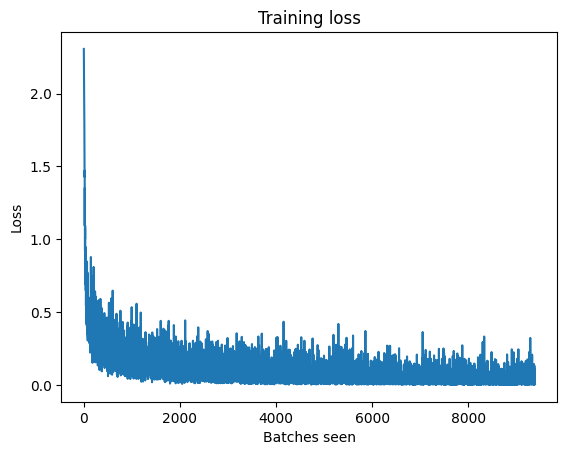

In [10]:
# Plot Losses
x_axis = np.arange(0, len(ls_losses), 1)
plt.plot(x_axis, ls_losses)
plt.xlabel("Batches seen")
plt.ylabel("Loss")
plt.title("Training loss")
plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 8**
This block evaluates the model on the test dataset.\
<blue>**model.eval()**</blue> sets the model to <green>**evaluation mode**</green>, and <blue>**torch.no_grad()**</blue> stops the computation of gradients to save memory and speed up computations. We are only *testing* now, so nothing should be learned.
For each batch of test images:
1) <blue>**Data Movement**</blue>: Images and labels are moved to the <green>**device (CPU/GPU)**</green>.
2) <blue>**Forward Pass**</blue>: Images pass through the network to compute <green>**predictions**</green>.
3) <blue>**Accuracy Calculation**</blue>: The model's predictions are compared to the true labels, and the <green>**accuracy**</green> is calculated.
4) <blue>**Storing Results**</blue>: Predictions and true labels are saved to <green>**calculate metrics**</green> later.

At the end of testing, the accuracy of the model on the test dataset is printed.

Note: Replace the placeholders **"None"** with the appropriate code for data movement, prediction, and storing results. To store results, first move the tensors back to the CPU and convert them to numpy: `tensor.cpu().numpy()`.

In [11]:
# Testing the model
model.eval()  # Set the model to evaluation mode
all_preds = []
all_labels = []
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        # TODO: Move images and labels to the device
        #images = None  # Replace None with code to move images to the device
        images = images.to(device)
        #labels = None  # Replace None with code to move labels to the device
        labels = labels.to(device)

        #outputs = None  # Forward pass through the model
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        # TODO: Append predictions and labels for metrics
        #all_preds.extend(None)   # Append predictions to the list
        all_preds.extend(predicted.cpu().numpy())
        #all_labels.extend(None)  # Append actual labels to the list
        all_labels.extend(labels.cpu().numpy())

    print(f'Accuracy of the network on the test images: {100 * correct / total:.2f}%')

Accuracy of the network on the test images: 97.61%


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 9**
Accuracy alone does not tell the whole story, so we calculate more metrics. To understand them, take the digit **8** as an example:
1) <blue>**Accuracy**</blue>: Percentage of all images classified correctly.
2) <blue>**Precision**</blue>: Of all the images the model *called* an 8, how many really were 8s? (High precision = few false alarms.)
3) <blue>**Recall**</blue>: Of all the images that really *were* 8s, how many did the model find? (High recall = few misses.)
4) <blue>**F1-Score**</blue>: A single score that balances precision and recall (their <green>**harmonic mean**</green>).
5) With 10 digits, precision, recall and F1 are first computed <green>**for each digit**</green> and then averaged. In sklearn this is `average='macro'`. Without it, sklearn will raise an error for 10 classes.
6) The <blue>**confusion matrix**</blue> shows how many images of each true digit were predicted as each digit. It is visualized using a <green>**heatmap**</green>, where the <blue>**rows**</blue> represent <green>**true labels**</green>, and the <blue>**columns**</blue> represent <green>**predicted labels**</green>. The diagonal holds the correct predictions, so anything *off* the diagonal is a mistake.

Note: Replace the placeholders **"None"** with the appropriate code to calculate the metrics using sklearn and compute the confusion matrix.

Accuracy: 97.61%
Precision: 0.9761
Recall: 0.9757
F1-Score: 0.9759


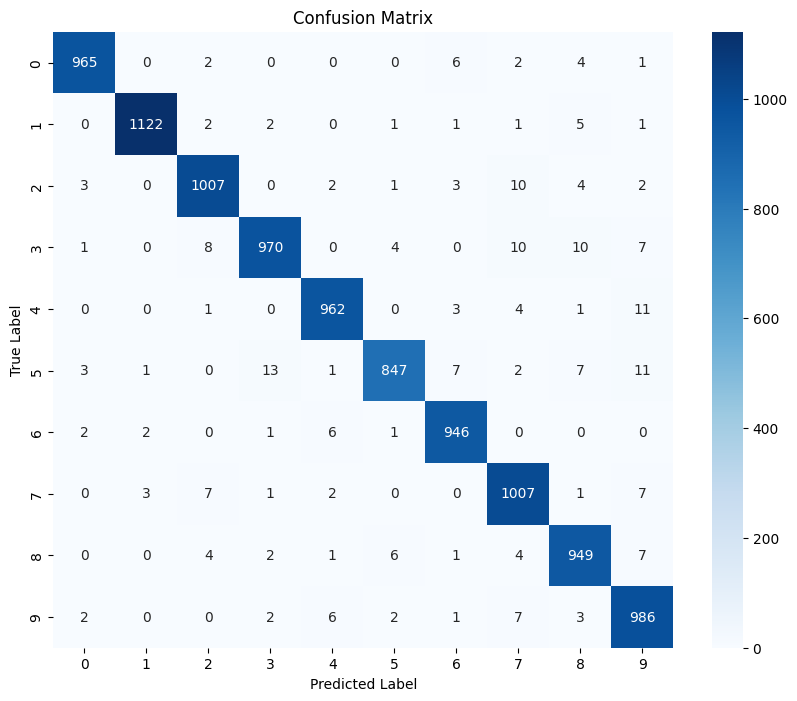

In [12]:
# TODO: Convert predictions and labels to numpy arrays for metric calculation
#all_preds = None   # Replace None with correct code to convert to numpy array
all_preds = np.array(all_preds)
#all_labels = None  # Replace None with correct code to convert to numpy array
all_labels = np.array(all_labels)

# Calculate accuracy, precision, recall, and F1-score
# TODO: Use sklearn to calculate the metrics (remember average='macro' for precision, recall and F1)
#accuracy = None   # Replace None with the correct calculation
accuracy = accuracy_score(all_labels, all_preds)
#precision = None  # Replace None with the correct calculation
precision = precision_score(all_labels, all_preds, average='macro')
#recall = None     # Replace None with the correct calculation
recall = recall_score(all_labels, all_preds, average='macro')
#f1 = None         # Replace None with the correct calculation
f1 = f1_score(all_labels, all_preds, average='macro')

print(f'Accuracy: {accuracy * 100:.2f}%')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1-Score: {f1:.4f}')

# TODO: Confusion matrix calculation
#conf_matrix = None  # Replace None with correct code to compute the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 10: Reflect**

Answer these in the text cell below, in your own words. Two or three sentences each is enough. There are no trick questions, but "it went down" is not an answer: say *what* you see in *your* plots.

**Q1.** Look at your loss plot from Step 7. How does the loss change from the first few hundred batches to the end of training? Why do you think the line is jagged instead of perfectly smooth?

**Q2.** Look at your confusion matrix. Which two digits does your model mix up most often? Suggest one reason why those two might be hard to tell apart.

**Q3.** We measured accuracy on the **test** images, not the training images. Why? What could go wrong if we only checked the training images?

**Q4.** Suppose Mary's job were to flag *dangerous* readings. Would you prefer a model with higher **precision** or higher **recall** for that job? Explain why.

**Your answers:**

**Q1:** The training loss decreases sharply from approximately 2.3 at the beginning to a much lower value as training progresses. This indicates that the ANN is learning to classify handwritten digits. The line is jagged because the model updates its weights after each batch, and different batches contain different images, resulting in variations in the loss.

**Q2:** My model most frequently confuses the digits 5 and 3, with 13 actual 5s incorrectly classified as 3s. Another common confusion is between 3 and 2, with 8 actual 3s incorrectly classified as 2s. These digits can be difficult to distinguish because handwritten styles vary, and some digits may have similar curves or strokes.

**Q3:** We evaluate the model on test images to measure how well it performs on images it has never seen during training. If we only evaluated it on training images, the model might memorize the training examples and achieve high accuracy without learning patterns that generalize to new handwritten digits. Testing on unseen data gives us a more reliable estimate of its ability to recognize new images.

**Q4:** I would prefer higher recall when detecting dangerous readings because failing to identify a genuinely dangerous reading could have serious consequences. High recall helps the model detect more of the actual dangerous cases, even if it occasionally raises a false alarm for a harmless reading. Ideally, I would also aim for high precision to minimize unnecessary alarms.

In [13]:
# Mission status
print(f"Neural core restored to {accuracy * 100:.1f}%")

Neural core restored to 97.6%
